# MCM perturbation 데이터 둘러보기

세 GEO 데이터셋의 로컬 파일을 열어 **유전자 행, 표본 열, 발현량 단위와 조건 라벨**을 확인한다. 각 표의 개수는 파일의 **열 수**이며, 실제 독립 표본 수나 pairing은 GEO와 실험 메타데이터로 확정한다. 이 노트북에서는 로컬 원본을 읽어 구조와 품질 지표를 미리 본다.

**읽는 순서** · 파일 목록 → GSE175485 (mouse, counts/log2FPKM) → GSE228927 (mouse, FPKM) → GSE282665 (human, TPM) → 데이터 간 비교

[분석 방법과 재실행 안내](README.md)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

repo = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "data" / "perturbation_validation").is_dir()),
    None,
)
if repo is None:
    raise FileNotFoundError("저장소 루트 또는 notebooks/perturbation에서 실행하세요.")
data = repo / "data" / "perturbation_validation"

inventory = pd.DataFrame([
    {
        "dataset": path.parent.name,
        "file": path.name,
        "MiB": round(path.stat().st_size / 2**20, 2),
        "format": "Excel" if path.suffix == ".xlsx" else "tab-delimited text",
    }
    for path in sorted(data.glob("GSE*/*"))
    if path.is_file() and path.suffix.lower() in {".xlsx", ".xls", ".tsv"}
])
display(inventory)

/data/home/swkim0523/.local/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/data/home/swkim0523/.local/lib/python3.9/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.4' currently installed).
  from pandas.core import (


,dataset,file,MiB,format
0,GSE175485,GSE175485_Sup_file_2.xlsx,0.39,Excel
1,GSE175485,GSE175485_analysis.xlsx,7.91,Excel
2,GSE175485,GSE175485_sup_file_3.xlsx,0.06,Excel
3,GSE228927,GSE228927_FPKM_anno.xls,15.41,tab-delimited text
4,GSE282665,GSE282665_astrocyte.GSE282665_microglia.media....,8.68,tab-delimited text
5,GSE282665,GSE282665_microglia.cxcr4.gpnmb.sirna.salmon.m...,6.47,tab-delimited text
6,GSE282665,GSE282665_motor.neuron.GSE282665_microglia.med...,12.53,tab-delimited text


## GSE175485 · Mouse astrocyte

`GSE175485_analysis.xlsx`의 master sheet에는 **유전자 주석**, **저자가 계산한 비교별 DE 결과**, **표본별 log2FPKM**, **표본별 raw counts**가 함께 있다. 위쪽 헤더는 블록 라벨이 중앙에 있고, 아래쪽 헤더에 실제 열 이름이 있다. 두 발현 블록은 같은 표본의 서로 다른 발현량 표현이다. `MCM_PBS`와 `MCM_LPS`가 예정 비교이며 `ECM`은 endothelial-conditioned medium이다.

In [2]:
gse175 = data / "GSE175485"
with pd.ExcelFile(gse175 / "GSE175485_analysis.xlsx", engine="openpyxl") as book:
    print("Master workbook sheets:", book.sheet_names)
    raw_workbook = book.parse("1. RNA Seq Master List", header=None)

for name in ("GSE175485_Sup_file_2.xlsx", "GSE175485_sup_file_3.xlsx"):
    with pd.ExcelFile(gse175 / name, engine="openpyxl") as book:
        print(f"{name}: {', '.join(book.sheet_names)}")

# The 12 sample labels repeat across the adjacent log2FPKM and count blocks.
excel_headers = raw_workbook.iloc[1].astype(str)
is_sample = excel_headers.str.fullmatch(r"(?:MCM|ECM)_(?:PBS|LPS)_.+")
sample_positions = excel_headers.index[is_sample].tolist()
if len(sample_positions) != 24:
    raise ValueError(f"Expected two blocks of 12 expression columns; found {len(sample_positions)}")
log_positions, count_positions = sample_positions[:12], sample_positions[12:]
log_names = excel_headers.loc[log_positions].tolist()
count_names = excel_headers.loc[count_positions].tolist()
assert [name.rsplit("_", 1)[0] if name not in log_names else name
        for name in count_names] == log_names
assert raw_workbook.iloc[0, log_positions].eq("log2FPKM").any()
assert raw_workbook.iloc[0, count_positions].eq("Raw counts").any()

gene_symbols = pd.Index(raw_workbook.iloc[2:, 0], name="GeneSymbol")

def excel_expression(positions, column_names):
    values = raw_workbook.iloc[2:, positions].apply(pd.to_numeric, errors="raise")
    values.index = gene_symbols
    values.columns = column_names
    return values

counts_175 = excel_expression(count_positions, count_names)
logfpkm_175 = excel_expression(log_positions, log_names)
samples_175 = pd.DataFrame({
    "count_column": count_names,
    "log2FPKM_column": log_names,
    "medium": [name.split("_")[0] for name in log_names],
    "stimulus": [name.split("_")[1] for name in log_names],
})
samples_175["condition"] = samples_175["medium"] + "_" + samples_175["stimulus"]

display(samples_175)
display(pd.crosstab(samples_175["medium"], samples_175["stimulus"]))

Master workbook sheets: ['ReadMe', '1. RNA Seq Master List']


GSE175485_Sup_file_2.xlsx: RNA ECM Uniqu, RNA MCM Unique, RNA ECM_MCM_Common
GSE175485_sup_file_3.xlsx: David Bioinformatics ECM, David Bioinformatics MCM, IPA MCM, IPA ECM, IPA Unique ECM, IPA Unique MCM


,count_column,log2FPKM_column,medium,stimulus,condition
0,ECM_PBS_1_S13,ECM_PBS_1_S13,ECM,PBS,ECM_PBS
1,ECM_PBS_2_S14,ECM_PBS_2_S14,ECM,PBS,ECM_PBS
2,ECM_PBS_3_S15,ECM_PBS_3_S15,ECM,PBS,ECM_PBS
3,ECM_LPS_1_S16,ECM_LPS_1_S16,ECM,LPS,ECM_LPS
4,ECM_LPS_2_S29,ECM_LPS_2_S29,ECM,LPS,ECM_LPS
5,ECM_LPS_3_S30,ECM_LPS_3_S30,ECM,LPS,ECM_LPS
6,MCM_PBS_1_S31_7,MCM_PBS_1_S31,MCM,PBS,MCM_PBS
7,MCM_PBS_2_S32_8,MCM_PBS_2_S32,MCM,PBS,MCM_PBS
8,MCM_PBS_3_S33_9,MCM_PBS_3_S33,MCM,PBS,MCM_PBS
9,MCM_LPS_1-NEW_S34_10,MCM_LPS_1-NEW_S34,MCM,LPS,MCM_LPS


stimulus,LPS,PBS
medium,,
ECM,3,3
MCM,3,3


In [3]:
# Show the gene identifiers and a few source values from both expression blocks.
first_sample_position = sample_positions[0]
display(pd.DataFrame({
    "first_header_row": raw_workbook.iloc[0, :first_sample_position].to_numpy(),
    "second_header_row": excel_headers.iloc[:first_sample_position].to_numpy(),
}).fillna(""))
mcm_rows = samples_175.loc[samples_175["medium"].eq("MCM")]
print("Raw counts · first five genes, MCM columns")
display(counts_175.loc[:, mcm_rows["count_column"]].head())
print("Published log2FPKM · same five genes and MCM samples")
display(logfpkm_175.loc[:, mcm_rows["log2FPKM_column"]].head().round(3))

,first_header_row,second_header_row
0,Gene information,GeneSymbol
1,,Chr
2,,Start
3,,End
4,,Strand
5,,Length
6,,Description
7,ECM_LPS vs ECM_PBS,foldchange
8,,log2FC
9,,PValue


Raw counts · first five genes, MCM columns


,MCM_PBS_1_S31_7,MCM_PBS_2_S32_8,MCM_PBS_3_S33_9,MCM_LPS_1-NEW_S34_10,MCM_LPS_2_S35_11,MCM_LPS_3_S36_12
GeneSymbol,,,,,,
Lum,115,26,19,20,41,14
Cfi,17,22,19,5,33,21
Hcn4,13,42,27,25,10,5
Mmp12,55,70,57,11,24,60
Dcn,222,206,99,533,249,174


Published log2FPKM · same five genes and MCM samples


,MCM_PBS_1_S31,MCM_PBS_2_S32,MCM_PBS_3_S33,MCM_LPS_1-NEW_S34,MCM_LPS_2_S35,MCM_LPS_3_S36
GeneSymbol,,,,,,
Lum,0.384,-1.541,-2.387,-1.662,-0.970,-2.313
Cfi,-2.228,-1.762,-2.386,-3.367,-1.265,-1.785
Hcn4,-3.440,-1.760,-2.806,-2.235,-3.683,-4.392
Mmp12,-1.449,-0.974,-1.725,-3.236,-2.493,-1.149
Dcn,1.314,1.349,-0.165,2.959,1.569,1.150


## GSE228927 · Mouse astrocyte

`.xls` 확장자를 쓰지만 파일은 **탭으로 구분된 텍스트**다. 각 행은 유전자이고, 표본 열에는 FPKM이 들어 있다. 뒤쪽에는 설명, GO, pathway 등의 유전자 주석이 있다. **`NOT1–3`는 resting-MCM 처리군**이며 LPS와 hemin 비교에서 같은 대조군을 사용한다.

In [4]:
table_228 = pd.read_csv(
    data / "GSE228927" / "GSE228927_FPKM_anno.xls", sep="\t", low_memory=False
).set_index("id")
headers_228 = table_228.columns.to_series().str.extract(r"^(?P<label>Hemin|LPS|NOT)(?P<suffix>\d+)$").dropna()
samples_228 = headers_228.rename_axis("expression_column").reset_index()
samples_228["condition"] = samples_228["label"].map({
    "Hemin": "hemin-MCM", "LPS": "LPS-MCM", "NOT": "resting-MCM"
})
fpkm_228 = table_228.loc[:, samples_228["expression_column"]]
annotation_228 = table_228.drop(columns=fpkm_228.columns)

display(samples_228)
display(samples_228.groupby("condition", sort=False).size().rename("file_columns").to_frame())
display(fpkm_228.head().round(3))
print("Annotation columns:", ", ".join(annotation_228.columns))

,expression_column,label,suffix,condition
0,Hemin1,Hemin,1,hemin-MCM
1,Hemin2,Hemin,2,hemin-MCM
2,Hemin3,Hemin,3,hemin-MCM
3,LPS1,LPS,1,LPS-MCM
4,LPS2,LPS,2,LPS-MCM
5,LPS3,LPS,3,LPS-MCM
6,NOT1,NOT,1,resting-MCM
7,NOT2,NOT,2,resting-MCM
8,NOT3,NOT,3,resting-MCM


,file_columns
condition,
hemin-MCM,3
LPS-MCM,3
resting-MCM,3


,Hemin1,Hemin2,Hemin3,LPS1,LPS2,LPS3,NOT1,NOT2,NOT3
id,,,,,,,,,
0610009B22Rik,14.631,15.503,14.032,15.904,12.836,13.037,13.654,15.857,19.353
0610010F05Rik,2.501,2.520,2.141,2.068,1.847,2.249,3.132,3.270,3.864
0610010K14Rik,18.482,21.939,20.084,19.154,19.347,22.543,23.737,17.710,19.889
0610012G03Rik,12.655,14.307,10.998,8.979,12.470,8.070,11.433,10.598,13.548
0610030E20Rik,4.515,4.829,4.650,5.784,5.213,5.518,5.282,4.982,6.383


Annotation columns: gene_Dbxref, description, GO_id, GO_term, pathway, pathway_description, TF_family


## GSE282665 · Human astrocyte와 motor neuron

두 파일 모두 `gene_id`(Ensembl ID)와 `gene_name`(symbol) 뒤에 Salmon gene-level **TPM** 표본 열이 있다. 열 이름에서 stimulus와 배지 라벨의 위치가 서로 다르다.

| Recipient | 원본 패턴 | 원본 열 예 |
| --- | --- | --- |
| Astrocyte | `prefix_media_stimulus` | `ctrl1_ctrl_lps`, `ctrl1_nil_untx` |
| Motor neuron | `prefix_stimulus_media` | `ctrl3_lps_ctrl`, `ctrl3_untx_fresh` |

아래 표의 `ctrl`, `vcp`, `fresh`, `nil`은 **파일 헤더에 있는 라벨**이다. `ctrl` 배지 후보가 motor neuron에서 조건당 6열로 보이지만, 논문 Fig. S7의 healthy-control 비교는 조건당 3 line을 보고한다. 따라서 접두어와 배지 라벨은 후보 열을 찾는 데 사용하며, recipient/source genotype과 pairing은 메타데이터로 확인한다. 별도의 microglia siRNA 파일은 파일 목록과 크기 비교에 포함한다. [Clarke et al., Fig. S7](https://doi.org/10.1186/s13024-024-00773-1)

In [5]:
gse282 = data / "GSE282665"
human_tables = {
    "astrocyte": pd.read_csv(
        gse282 / "GSE282665_astrocyte.GSE282665_microglia.media.salmon.merged.gene_tpm.tsv",
        sep="\t", low_memory=False, keep_default_na=False,
    ).set_index("gene_id"),
    "motor neuron": pd.read_csv(
        gse282 / "GSE282665_motor.neuron.GSE282665_microglia.media.salmon.merged.gene_tpm.tsv",
        sep="\t", low_memory=False, keep_default_na=False,
    ).set_index("gene_id"),
    "microglia siRNA": pd.read_csv(
        gse282 / "GSE282665_microglia.cxcr4.gpnmb.sirna.salmon.merged.gene_tpm.tsv",
        sep="\t", low_memory=False, keep_default_na=False,
    ).set_index("gene_id"),
}

human_expression = {
    recipient: table.drop(columns="gene_name") for recipient, table in human_tables.items()
}
samples_282 = {}
for recipient, columns in (
    ("astrocyte", ["prefix", "media_label", "stimulus"]),
    ("motor neuron", ["prefix", "stimulus", "media_label"]),
):
    names = human_expression[recipient].columns.to_series(index=None)
    labels = names.str.rsplit("_", n=2, expand=True)
    labels.columns = columns
    labels.insert(0, "expression_column", names)
    labels["condition"] = labels["media_label"] + " / " + labels["stimulus"]
    samples_282[recipient] = labels.reset_index(drop=True)

    print(f"{recipient} · 헤더 라벨별 열 수")
    display(pd.crosstab(labels["media_label"], labels["stimulus"]))
    # Pivot the exact column names so both conditions can be inspected side by side.
    display(labels.pivot(index=["prefix", "media_label"], columns="stimulus", values="expression_column"))
    first_cols = human_expression[recipient].columns[:3]
    display(human_tables[recipient].loc[:, ["gene_name", *first_cols]].head().round(3))

print("microglia siRNA · 원본 열 순서")
print(", ".join(human_expression["microglia siRNA"].columns))

astrocyte · 헤더 라벨별 열 수


stimulus,lps,untx
media_label,,
ctrl,4,4
nil,4,4
vcp,4,4


stimulus                       lps             untx
prefix media_label                                 
ctrl1  ctrl         ctrl1_ctrl_lps  ctrl1_ctrl_untx
       nil           ctrl1_nil_lps   ctrl1_nil_untx
       vcp           ctrl1_vcp_lps   ctrl1_vcp_untx
ctrl2  ctrl         ctrl2_ctrl_lps  ctrl2_ctrl_untx
       nil           ctrl2_nil_lps   ctrl2_nil_untx
       vcp           ctrl2_vcp_lps   ctrl2_vcp_untx
ctrl4  ctrl         ctrl4_ctrl_lps  ctrl4_ctrl_untx
       nil           ctrl4_nil_lps   ctrl4_nil_untx
       vcp           ctrl4_vcp_lps   ctrl4_vcp_untx
ctrl6  ctrl         ctrl6_ctrl_lps  ctrl6_ctrl_untx
       nil           ctrl6_nil_lps   ctrl6_nil_untx
       vcp           ctrl6_vcp_lps   ctrl6_vcp_untx

,gene_name,ctrl1_ctrl_lps,ctrl1_ctrl_untx,ctrl1_nil_lps
gene_id,,,,
ENSG00000000003,TSPAN6,27.688,27.174,35.982
ENSG00000000005,TNMD,0.036,0.040,0.157
ENSG00000000419,DPM1,56.977,46.992,61.950
ENSG00000000457,SCYL3,3.466,3.644,3.952
ENSG00000000460,C1orf112,6.793,8.124,5.740


motor neuron · 헤더 라벨별 열 수


stimulus,lps,untx
media_label,,
ctrl,6,6
fresh,6,6
vcp,6,6


stimulus                        lps              untx
prefix media_label                                   
cb1d   ctrl           cb1d_lps_ctrl    cb1d_untx_ctrl
       fresh         cb1d_lps_fresh   cb1d_untx_fresh
       vcp             cb1d_lps_vcp     cb1d_untx_vcp
cb1e   ctrl           cb1e_lps_ctrl    cb1e_untx_ctrl
       fresh         cb1e_lps_fresh   cb1e_untx_fresh
       vcp             cb1e_lps_vcp     cb1e_untx_vcp
ctrl3  ctrl          ctrl3_lps_ctrl   ctrl3_untx_ctrl
       fresh        ctrl3_lps_fresh  ctrl3_untx_fresh
       vcp            ctrl3_lps_vcp    ctrl3_untx_vcp
ctrl4  ctrl          ctrl4_lps_ctrl   ctrl4_untx_ctrl
       fresh        ctrl4_lps_fresh  ctrl4_untx_fresh
       vcp            ctrl4_lps_vcp    ctrl4_untx_vcp
ctrl5  ctrl          ctrl5_lps_ctrl   ctrl5_untx_ctrl
       fresh        ctrl5_lps_fresh  ctrl5_untx_fresh
       vcp            ctrl5_lps_vcp    ctrl5_untx_vcp
glia   ctrl           glia_lps_ctrl    glia_untx_ctrl
       fresh         glia_lps_fresh   glia_untx_fresh
       vcp             glia_lps_vcp     glia_untx_vcp

,gene_name,cb1d_lps_ctrl,cb1d_lps_fresh,cb1d_lps_vcp
gene_id,,,,
ENSG00000000003,TSPAN6,23.428,19.482,23.407
ENSG00000000005,TNMD,0.178,0.218,0.694
ENSG00000000419,DPM1,35.565,37.805,32.740
ENSG00000000457,SCYL3,5.908,6.693,6.667
ENSG00000000460,C1orf112,5.626,4.768,5.163


microglia siRNA · 원본 열 순서
cb1e_cxcr4, cb1e_gpnmb, cb1e_scramble, ctrl1_cxcr4, ctrl1_gpnmb, ctrl1_scramble, ctrl4_cxcr4, ctrl4_gpnmb, ctrl4_scramble, ctrl5_gpnmb, ctrl5_scramble, glia_cxcr4, glia_gpnmb, glia_scramble, glib_cxcr4, glib_gpnmb, glib_scramble, vcpf10_cxcr4, vcpf10_scramble


## 파일 구조와 표본별 발현 확인

`gene_rows`는 원본에서 읽은 유전자 행 수다. 인간 TPM 파일에서 동일한 symbol이 여러 Ensembl ID에 붙는 경우를 살펴보기 위해 ID와 symbol의 중복 수를 따로 표시한다. 아래 그래프는 선형 발현 행렬에서 값이 **0보다 큰 유전자 비율**을 표본 열마다 보여준다. 데이터셋 간 유전자 목록과 정량화 기준이 다르므로 점은 각 패널 안에서 비교한다.

In [6]:
matrix_specs = [
    ("GSE175485 / astrocyte · raw counts", counts_175, "counts", None),
    ("GSE175485 / astrocyte · log2FPKM", logfpkm_175, "log2FPKM", None),
    ("GSE228927 / astrocyte", fpkm_228, "FPKM", None),
    *[(f"GSE282665 / {recipient}", expression, "TPM", human_tables[recipient]["gene_name"])
      for recipient, expression in human_expression.items()],
]
matrix_summary = []
for label, expression, scale, symbols in matrix_specs:
    values = expression.to_numpy(dtype=float)
    invalid = ~np.isfinite(values)
    matrix_summary.append({
        "matrix": label,
        "scale": scale,
        "gene_rows": len(expression),
        "expression_columns": expression.shape[1],
        "repeated_gene_key_rows": expression.index.duplicated().sum(),
        "repeated_symbol_rows": (pd.NA if symbols is None
                                 else symbols[symbols.ne("")].duplicated().sum()),
        "nonfinite_values": invalid.sum(),
        "negative_values": (values < 0).sum(),
        "min": np.nanmin(values),
        "max": np.nanmax(values),
    })
display(pd.DataFrame(matrix_summary).round(3))

,matrix,scale,gene_rows,expression_columns,repeated_gene_key_rows,repeated_symbol_rows,nonfinite_values,negative_values,min,max
0,GSE175485 / astrocyte · raw counts,counts,14205,12,0,<NA>,0,0,0.00,1275651.000
1,GSE175485 / astrocyte · log2FPKM,log2FPKM,14205,12,0,<NA>,0,24449,-7.92,12.570
2,GSE228927 / astrocyte,FPKM,17730,9,0,<NA>,0,0,0.00,13429.405
3,GSE282665 / astrocyte,TPM,60676,24,0,34,0,0,0.00,18521.013
4,GSE282665 / motor neuron,TPM,60676,36,0,34,0,0,0.00,27665.563
5,GSE282665 / microglia siRNA,TPM,60676,19,0,34,0,0,0.00,79955.350


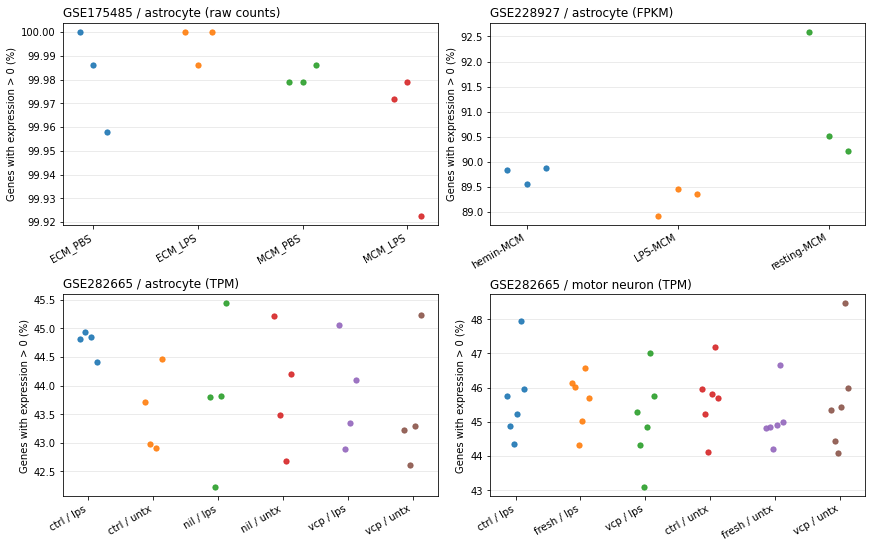

In [7]:
def plot_detected_fraction(ax, expression, labels, title):
    labels = labels.reindex(expression.columns)
    if labels.isna().any():
        raise ValueError(f"{title}: condition labels do not match expression columns")
    order = labels.drop_duplicates().tolist()
    fraction = expression.gt(0).mean(axis=0) * 100
    for pos, condition in enumerate(order):
        values = fraction[labels.eq(condition)]
        offsets = np.linspace(-0.13, 0.13, len(values)) if len(values) > 1 else [0]
        ax.scatter(pos + offsets, values, s=27, alpha=0.9)
    ax.set_xticks(range(len(order)), order, rotation=30, ha="right")
    ax.set_ylabel("Genes with expression > 0 (%)")
    ax.set_title(title, loc="left")
    ax.grid(axis="y", color="0.9")
    ax.set_axisbelow(True)

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), layout="constrained")
plot_detected_fraction(
    axes[0, 0], counts_175, samples_175.set_index("count_column")["condition"],
    "GSE175485 / astrocyte (raw counts)",
)
plot_detected_fraction(
    axes[0, 1], fpkm_228, samples_228.set_index("expression_column")["condition"],
    "GSE228927 / astrocyte (FPKM)",
)
for ax, recipient in zip(axes[1], ("astrocyte", "motor neuron")):
    plot_detected_fraction(
        ax, human_expression[recipient], samples_282[recipient].set_index("expression_column")["condition"],
        f"GSE282665 / {recipient} (TPM)",
    )
plt.show()

다음 분석에서는 여기서 확인한 열을 GEO sample ID 및 생물학적 실험 단위에 연결한다. 이후 ACHES, SNAP-a, SNAP-n 점수에 사용할 최종 조건과 표본을 `sample_manifest.tsv`에 기록한다.